In [12]:
from langgraph.graph import StateGraph, START, END, add_messages
from typing import TypedDict, Annotated
from langchain_core.messages import AnyMessage, HumanMessage
from langchain_groq import ChatGroq
import os
from dotenv import load_dotenv
from langgraph.checkpoint.memory import InMemorySaver

In [13]:
class ChatState(TypedDict):
    messages:Annotated[list[AnyMessage], add_messages] 

In [14]:
load_dotenv()

True

In [15]:
llm = ChatGroq(model="openai/gpt-oss-120b", temperature=0.2, api_key=os.getenv("GROQ_API_KEY"))

In [16]:
def chat_node(state: ChatState):
    messages= state['messages']
    
    response=llm.invoke(messages)
    
    return {'messages':[response]}
    

In [17]:
checkpointer=InMemorySaver()
graph = StateGraph(ChatState)

graph.add_node("chat_node", chat_node)

graph.add_edge(START, 'chat_node')
graph.add_edge("chat_node", END)

In [23]:
chatbot= graph.compile(checkpointer=checkpointer)

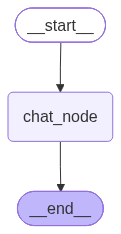

In [24]:
chatbot

In [25]:
initial_state={
    "messages":[HumanMessage(content="what is capital of india")]
}
chatbot.invoke(initial_state)['messages'][-1].content

ValueError: Checkpointer requires one or more of the following 'configurable' keys: thread_id, checkpoint_ns, checkpoint_id

In [30]:
thread_id='2'
while True:
    user_msg= input('type here')
    print(user_msg)
    if user_msg.strip().lower()in ['quite', 'exit', 'bye']:
        break
    config1={"configurable":{"thread_id":thread_id}}
    response=chatbot.invoke({'messages':[HumanMessage(content=user_msg)]},config=config1) 
    print("AI message:",response['messages'][-1].content)

hi my name is adhira
AI message: Hi Adhira! Nice to meet you. How can I help you today?
tell me my name
AI message: Your name is Adhira.
bye


In [31]:
chatbot.get_state(config1)

StateSnapshot(values={'messages': [HumanMessage(content='hi my name is adhira', additional_kwargs={}, response_metadata={}, id='84805d99-d477-4c07-80ef-9060da9393d0'), AIMessage(content='Hi Adhira! Nice to meet you. How can I help you today?', additional_kwargs={'reasoning_content': 'The user says "hi my name is adhira". We need to respond appropriately. It\'s a simple greeting. We can respond friendly, ask how can help. No policy issues.'}, response_metadata={'token_usage': {'completion_tokens': 63, 'prompt_tokens': 77, 'total_tokens': 140, 'completion_time': 0.132495843, 'completion_tokens_details': {'reasoning_tokens': 37}, 'prompt_time': 0.037586564, 'prompt_tokens_details': None, 'queue_time': 0.775294492, 'total_time': 0.170082407}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_b1dd3e7a63', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1c0dd-82c6-75ea-9189-74bbfddde997-0', tool_calls=[], invalid_

In [32]:
list(chatbot.get_state_history(config1))

[StateSnapshot(values={'messages': [HumanMessage(content='hi my name is adhira', additional_kwargs={}, response_metadata={}, id='84805d99-d477-4c07-80ef-9060da9393d0'), AIMessage(content='Hi Adhira! Nice to meet you. How can I help you today?', additional_kwargs={'reasoning_content': 'The user says "hi my name is adhira". We need to respond appropriately. It\'s a simple greeting. We can respond friendly, ask how can help. No policy issues.'}, response_metadata={'token_usage': {'completion_tokens': 63, 'prompt_tokens': 77, 'total_tokens': 140, 'completion_time': 0.132495843, 'completion_tokens_details': {'reasoning_tokens': 37}, 'prompt_time': 0.037586564, 'prompt_tokens_details': None, 'queue_time': 0.775294492, 'total_time': 0.170082407}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_b1dd3e7a63', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1c0dd-82c6-75ea-9189-74bbfddde997-0', tool_calls=[], invalid